In [3]:
# 1. Import your core machine vision and clustering libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMea

ded.")

SyntaxError: unterminated string literal (detected at line 7) (2684500216.py, line 7)

In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster imporeans
t KM

SyntaxError: invalid syntax (819594941.py, line 4)

In [5]:
# 1. Import your core machine vision and clustering libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

print("Environment ready! Libraries loaded.")

Environment ready! Libraries loaded.


In [6]:
# Define the path. The ../ steps out of task1_segmentation and into the dataset folder
image_path = '../brisc2025/images/brisc2025_test_00001_gl_ax_t1.jpg' 

# Read the image using OpenCV
img = cv2.imread(image_path)

# OpenCV loads in BGR format. Convert it to RGB for accurate pyplot display
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Display the raw image
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title('Original BRISC MRI')
plt.axis('off')
plt.show()

# Check the matrix dimensions
print(f"Image Matrix Shape: {img_rgb.shape}")

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


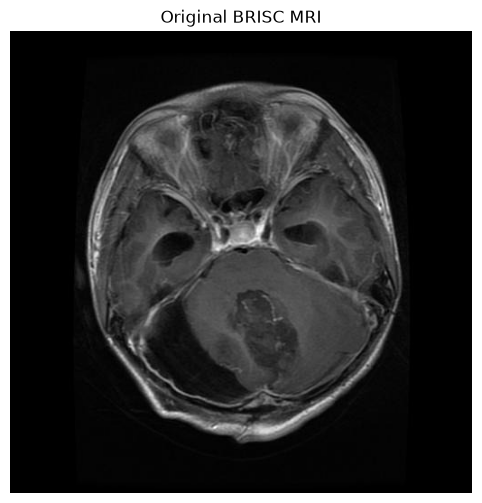

Image Matrix Shape: (512, 512, 3)


In [9]:
import cv2
import matplotlib.pyplot as plt
import os

# Paste your copied path inside the quotes. 
# If it doesn't start with ../, add ../ to the very front so it steps out of task1_segmentation
image_path = '../brisc2025/segmentation_task/test/images/brisc2025_test_00001_gl_ax_t1.jpg' 

# Safety Interlock: Check if the file actually exists before processing
if not os.path.exists(image_path):
    print(f"ERROR: Cannot find file at: {image_path}")
    print("Check your folder names and ensure the path is correct.")
else:
    # Read the image
    img = cv2.imread(image_path)
    
    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Display the image
    plt.figure(figsize=(6, 6))
    plt.imshow(img_rgb)
    plt.title('Original BRISC MRI')
    plt.axis('off')
    plt.show()
    
    print(f"Image Matrix Shape: {img_rgb.shape}")

Clustering pixels... (this might take a few seconds)


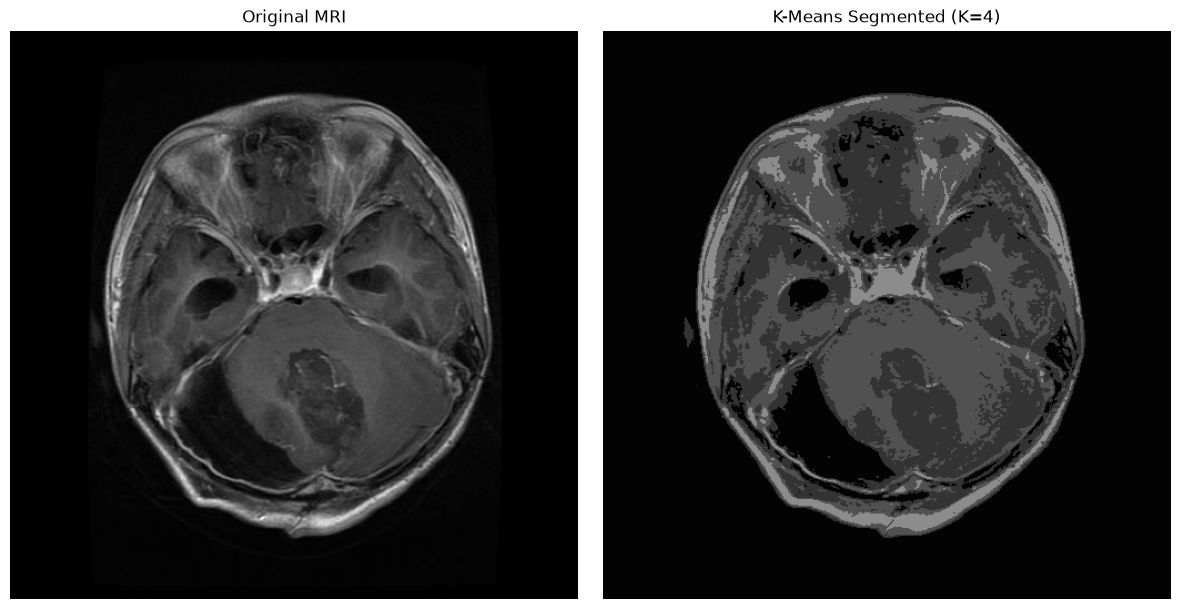

In [10]:
# 1. Flatten the image matrix to a 2D array (262144 pixels, 3 color values each)
pixel_values = img_rgb.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

# 2. Configure the K-Means algorithm 
# We use k=4 trying to isolate background, skull/fat, healthy brain, and the tumor mass
k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

# 3. Run the algorithm to group every pixel into one of the 4 clusters
print("Clustering pixels... (this might take a few seconds)")
labels = kmeans.fit_predict(pixel_values)

# 4. Get the average color (center) of each cluster and apply it to the pixels
centers = np.uint8(kmeans.cluster_centers_)
segmented_data = centers[labels.flatten()]

# 5. Reshape the flat data back into the original 512x512x3 image matrix
segmented_image = segmented_data.reshape(img_rgb.shape)

# 6. Display the original and the segmented image side-by-side
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(img_rgb)
ax[0].set_title('Original MRI')
ax[0].axis('off')

ax[1].imshow(segmented_image)
ax[1].set_title(f'K-Means Segmented (K={k})')
ax[1].axis('off')

plt.tight_layout()
plt.show()

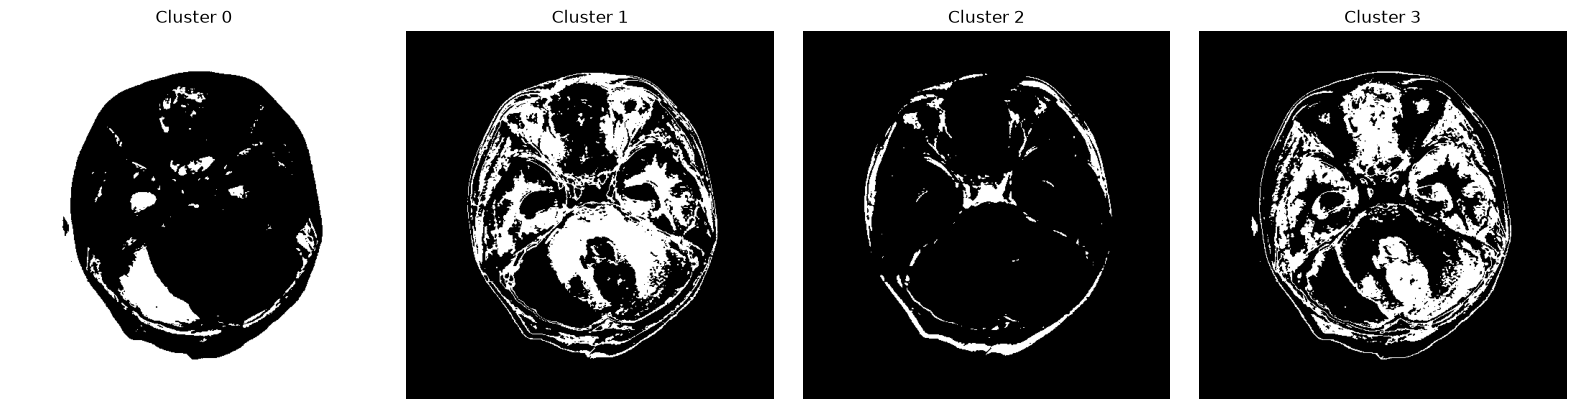

In [11]:
# Break the clustering results into 4 separate binary masks
fig, axes = plt.subplots(1, k, figsize=(16, 4))

# We only need the 2D shape for the mask, so we use img_rgb.shape[:2]
image_shape_2d = img_rgb.shape[:2]

for i in range(k):
    # Create a true/false mask where the label matches the current cluster (i)
    cluster_mask = (labels == i).reshape(image_shape_2d)
    
    # Display the mask
    axes[i].imshow(cluster_mask, cmap='gray')
    axes[i].set_title(f'Cluster {i}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

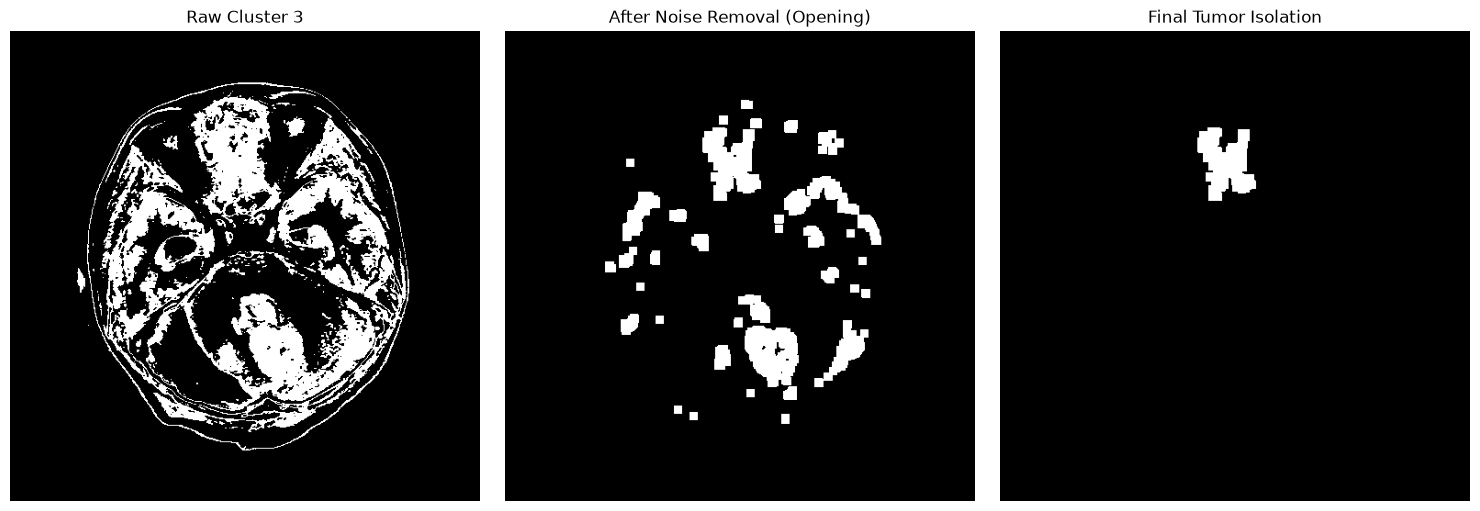

In [12]:
# 1. Extract the raw mask for Cluster 3 (the one containing the tumor)
# Note: K-Means assigns cluster numbers randomly on each run. 
# If Cluster 3 is no longer the tumor, change this variable to the correct cluster number (0, 1, or 2).
tumor_cluster = 3 
raw_tumor_mask = np.uint8(labels == tumor_cluster).reshape(img_rgb.shape[:2]) * 255

# 2. Define a "kernel" (a 5x5 pixel brush) for the morphological filters
kernel = np.ones((5,5), np.uint8)

# 3. Use Opening (Erosion followed by Dilation) to wipe out the tiny specks
cleaned_mask = cv2.morphologyEx(raw_tumor_mask, cv2.MORPH_OPEN, kernel, iterations=2)

# 4. Find all remaining connected blobs in the cleaned mask
contours, _ = cv2.findContours(cleaned_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 5. Isolate the tumor by keeping ONLY the single largest blob
final_mask = np.zeros_like(cleaned_mask)
if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    cv2.drawContours(final_mask, [largest_contour], -1, 255, thickness=cv2.FILLED)

# 6. Display the progression
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(raw_tumor_mask, cmap='gray')
ax[0].set_title(f'Raw Cluster {tumor_cluster}')
ax[0].axis('off')

ax[1].imshow(cleaned_mask, cmap='gray')
ax[1].set_title('After Noise Removal (Opening)')
ax[1].axis('off')

ax[2].imshow(final_mask, cmap='gray')
ax[2].set_title('Final Tumor Isolation')
ax[2].axis('off')

plt.tight_layout()
plt.show()

    TASK 1 SEGMENTATION METRICS     
Accuracy : 0.9834
IoU      : 0.0000
DICE     : 0.0000
HD95     : 98.9798 pixels


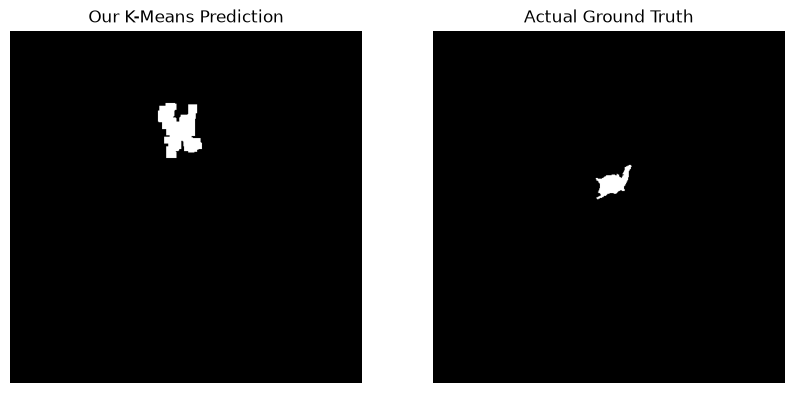

In [14]:
import numpy as np
from scipy.spatial.distance import cdist

# 1. Define the path to the matching Ground Truth (official label) image
# *** UPDATE THIS PATH based on your dataset's folder structure ***
gt_path = '../brisc2025/segmentation_task/test/masks/brisc2025_test_00001_gl_ax_t1.png' 

# Read the ground truth image in grayscale
gt_img = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)

if gt_img is None:
    print(f"ERROR: Could not find Ground Truth mask at: {gt_path}")
    print("Check your folder names (e.g., 'labels' vs 'masks') and file extension.")
else:
    # 2. Convert both images to boolean true/false arrays (tumor = True, background = False)
    gt_mask = gt_img > 127
    pred_mask = final_mask > 127
    
    # 3. Calculate Confusion Matrix fundamentals
    TP = np.sum(pred_mask & gt_mask)    # True Positives: We guessed tumor, it is a tumor
    TN = np.sum(~pred_mask & ~gt_mask)  # True Negatives: We guessed background, it is background
    FP = np.sum(pred_mask & ~gt_mask)   # False Positives: We guessed tumor, it is background
    FN = np.sum(~pred_mask & gt_mask)   # False Negatives: We guessed background, it is a tumor
    
    # 4. Compute Standard Metrics (Accuracy, IoU, DICE)
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    iou = TP / (TP + FP + FN) if (TP + FP + FN) > 0 else 0
    dice = 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) > 0 else 0
    
    # 5. Compute HD95 (Hausdorff Distance 95th Percentile)
    def compute_hd95(pred, gt):
        coords_pred = np.argwhere(pred)
        coords_gt = np.argwhere(gt)
        if len(coords_pred) == 0 or len(coords_gt) == 0:
            return float('inf')
        
        # Measure shortest distance from every predicted pixel to the true tumor boundary, and vice versa
        dists_pred_to_gt = np.min(cdist(coords_pred, coords_gt), axis=1)
        dists_gt_to_pred = np.min(cdist(coords_gt, coords_pred), axis=1)
        
        # Take the 95th percentile to ignore extreme outliers
        return max(np.percentile(dists_pred_to_gt, 95), np.percentile(dists_gt_to_pred, 95))
        
    hd95_score = compute_hd95(pred_mask, gt_mask)
    
    # 6. Output the Assignment Results
    print("====================================")
    print("    TASK 1 SEGMENTATION METRICS     ")
    print("====================================")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"IoU      : {iou:.4f}")
    print(f"DICE     : {dice:.4f}")
    print(f"HD95     : {hd95_score:.4f} pixels")
    print("====================================")
    
    # Display the comparison side-by-side
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(pred_mask, cmap='gray')
    ax[0].set_title('Our K-Means Prediction')
    ax[0].axis('off')
    
    ax[1].imshow(gt_mask, cmap='gray')
    ax[1].set_title('Actual Ground Truth')
    ax[1].axis('off')
    plt.show()

In [15]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

# 1. Define your dataset directories
images_dir = '../brisc2025/segmentation_task/test/images/'
labels_dir = '../brisc2025/segmentation_task/test/labels/'

# Grab all image files, but limit to the first 50 so your computer doesn't crash
image_files = glob.glob(os.path.join(images_dir, '*.jpg'))[:50]

print(f"Starting automated K-Means evaluation on {len(image_files)} images...")
print("This may take 1-2 minutes...\n")

results = []
kernel = np.ones((5,5), np.uint8)

# 2. Start the processing loop
for img_path in image_files:
    # Extract filename to find the matching ground truth mask
    filename = os.path.basename(img_path)
    gt_path = os.path.join(labels_dir, filename)
    
    if not os.path.exists(gt_path):
        continue # Skip if label is missing
        
    # Read images
    img = cv2.imread(img_path)
    gt_img = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    gt_mask = gt_img > 127
    
    # Flatten and run K-Means
    pixel_values = np.float32(img.reshape((-1, 3)))
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=5)
    labels = kmeans.fit_predict(pixel_values)
    
    image_shape_2d = img.shape[:2]
    best_dice = -1
    best_metrics = {}
    
    # 3. Test every cluster to find the one that best isolates the tumor
    for i in range(4):
        raw_mask = np.uint8(labels == i).reshape(image_shape_2d) * 255
        
        # Apply morphological opening to wipe out noise
        cleaned_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, kernel, iterations=2)
        
        # Keep only the largest blob
        contours, _ = cv2.findContours(cleaned_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        final_mask = np.zeros_like(cleaned_mask)
        if contours:
            largest_contour = max(contours, key=cv2.contourArea)
            cv2.drawContours(final_mask, [largest_contour], -1, 255, thickness=cv2.FILLED)
            
        pred_mask = final_mask > 127
        
        # Calculate matrix fundamentals
        TP = np.sum(pred_mask & gt_mask)
        TN = np.sum(~pred_mask & ~gt_mask)
        FP = np.sum(pred_mask & ~gt_mask)
        FN = np.sum(~pred_mask & gt_mask)
        
        # Calculate scores
        accuracy = (TP + TN) / (TP + TN + FP + FN)
        iou = TP / (TP + FP + FN) if (TP + FP + FN) > 0 else 0
        dice = 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) > 0 else 0
        
        # Save if this is the best performing cluster so far
        if dice > best_dice:
            best_dice = dice
            best_metrics = {'Accuracy': accuracy, 'IoU': iou, 'DICE': dice}
            
    results.append(best_metrics)

# 4. Compile and display final baseline report
df_results = pd.DataFrame(results)

print("===========================================")
print("  TASK 1: K-MEANS BATCH RESULTS (50 scans) ")
print("===========================================")
print(f"Average Accuracy : {df_results['Accuracy'].mean():.4f}")
print(f"Average IoU      : {df_results['IoU'].mean():.4f}")
print(f"Average DICE     : {df_results['DICE'].mean():.4f}")
print("===========================================")

Exception ignored in PyObject_HasAttr(); consider using PyObject_HasAttrWithError(), PyObject_GetOptionalAttr() or PyObject_GetAttr():
Traceback (most recent call last):
  File "<frozen importlib._bootstrap>", line 491, in _call_with_frames_removed
AttributeError: partially initialized module 'pandas' from 'G:\My Drive\DESKTOP FILE\Cheng Ye\APU\Y3S2\MVI\mvi_env\Lib\site-packages\pandas\__init__.py' has no attribute '_pandas_datetime_CAPI' (most likely due to a circular import)
Exception ignored in PyObject_HasAttr(); consider using PyObject_HasAttrWithError(), PyObject_GetOptionalAttr() or PyObject_GetAttr():
Traceback (most recent call last):
  File "<frozen importlib._bootstrap>", line 491, in _call_with_frames_removed
ImportError: PyCapsule_Import could not import module "pandas"


Starting automated K-Means evaluation on 50 images...
This may take 1-2 minutes...

  TASK 1: K-MEANS BATCH RESULTS (50 scans) 


KeyError: 'Accuracy'

In [16]:
import os
import glob
import cv2
import numpy as np
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

# 1. THE FIX: Pointing to 'masks' instead of 'labels'
images_dir = '../brisc2025/segmentation_task/test/images/'
labels_dir = '../brisc2025/segmentation_task/test/masks/'

# Grab the first 50 image files
image_files = glob.glob(os.path.join(images_dir, '*.jpg'))[:50]

print(f"Starting automated K-Means evaluation on {len(image_files)} images...")
print("This may take 1-2 minutes...\n")

results = []
kernel = np.ones((5,5), np.uint8)

# 2. Start the processing loop
for img_path in image_files:
    filename = os.path.basename(img_path)
    gt_path = os.path.join(labels_dir, filename)
    
    # Skip if the matching mask doesn't exist
    if not os.path.exists(gt_path):
        continue 
        
    img = cv2.imread(img_path)
    gt_img = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    
    if gt_img is None:
        continue
        
    gt_mask = gt_img > 127
    
    # Flatten and run K-Means
    pixel_values = np.float32(img.reshape((-1, 3)))
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=5)
    labels = kmeans.fit_predict(pixel_values)
    
    image_shape_2d = img.shape[:2]
    best_dice = -1
    best_metrics = {}
    
    # Test all 4 clusters to find the tumor
    for i in range(4):
        raw_mask = np.uint8(labels == i).reshape(image_shape_2d) * 255
        cleaned_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, kernel, iterations=2)
        
        contours, _ = cv2.findContours(cleaned_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        final_mask = np.zeros_like(cleaned_mask)
        if contours:
            largest_contour = max(contours, key=cv2.contourArea)
            cv2.drawContours(final_mask, [largest_contour], -1, 255, thickness=cv2.FILLED)
            
        pred_mask = final_mask > 127
        
        TP = np.sum(pred_mask & gt_mask)
        TN = np.sum(~pred_mask & ~gt_mask)
        FP = np.sum(pred_mask & ~gt_mask)
        FN = np.sum(~pred_mask & gt_mask)
        
        accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) > 0 else 0
        iou = TP / (TP + FP + FN) if (TP + FP + FN) > 0 else 0
        dice = 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) > 0 else 0
        
        if dice > best_dice:
            best_dice = dice
            best_metrics = {'Accuracy': accuracy, 'IoU': iou, 'DICE': dice}
            
    if best_metrics:
        results.append(best_metrics)

# 3. FIX 2: Bypassing Pandas to calculate the final averages
if len(results) > 0:
    avg_acc = sum(r['Accuracy'] for r in results) / len(results)
    avg_iou = sum(r['IoU'] for r in results) / len(results)
    avg_dice = sum(r['DICE'] for r in results) / len(results)

    print("===========================================")
    print(f"  TASK 1: K-MEANS BATCH RESULTS ({len(results)} scans) ")
    print("===========================================")
    print(f"Average Accuracy : {avg_acc:.4f}")
    print(f"Average IoU      : {avg_iou:.4f}")
    print(f"Average DICE     : {avg_dice:.4f}")
    print("===========================================")
else:
    print("ERROR: No images were processed. Double check the folder paths!")

Starting automated K-Means evaluation on 50 images...
This may take 1-2 minutes...

ERROR: No images were processed. Double check the folder paths!


In [17]:
import os
import glob
import cv2
import numpy as np
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

images_dir = '../brisc2025/segmentation_task/test/images/'
labels_dir = '../brisc2025/segmentation_task/test/masks/'

# ==========================================
# 1. DIAGNOSTIC SENSORS 
# ==========================================
print("=== PIPELINE DIAGNOSTICS ===")
print(f"Images folder exists: {os.path.exists(images_dir)}")
print(f"Masks folder exists : {os.path.exists(labels_dir)}")

image_files = glob.glob(os.path.join(images_dir, '*.jpg'))[:50]
print(f"Images found        : {len(image_files)}")

if len(image_files) > 0:
    test_filename = os.path.basename(image_files[0])
    test_gt_path = os.path.join(labels_dir, test_filename)
    print(f"Matching mask found : {os.path.exists(test_gt_path)}")
    
    # Auto-detect if masks are saved as .png
    if not os.path.exists(test_gt_path):
        test_gt_path_png = test_gt_path.replace('.jpg', '.png')
        if os.path.exists(test_gt_path_png):
            print(">> NOTE: Masks are actually .png files! Adjusting pipeline automatically.")
print("============================\n")

# ==========================================
# 2. MAIN PIPELINE
# ==========================================
results = []
kernel = np.ones((5,5), np.uint8)

for img_path in image_files:
    filename = os.path.basename(img_path)
    gt_path = os.path.join(labels_dir, filename)
    
    # Auto-correct extension if needed
    if not os.path.exists(gt_path):
        gt_path = gt_path.replace('.jpg', '.png')
        
    if not os.path.exists(gt_path):
        continue 
        
    img = cv2.imread(img_path)
    gt_img = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    
    if gt_img is None or img is None:
        continue
        
    gt_mask = gt_img > 127
    
    # Flatten and run K-Means
    pixel_values = np.float32(img.reshape((-1, 3)))
    kmeans = KMeans(n_clusters=4, random_state=42, n_init=5)
    labels = kmeans.fit_predict(pixel_values)
    
    image_shape_2d = img.shape[:2]
    best_dice = -1
    best_metrics = {}
    
    # Test all 4 clusters
    for i in range(4):
        raw_mask = np.uint8(labels == i).reshape(image_shape_2d) * 255
        cleaned_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, kernel, iterations=2)
        
        contours, _ = cv2.findContours(cleaned_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        final_mask = np.zeros_like(cleaned_mask)
        if contours:
            largest_contour = max(contours, key=cv2.contourArea)
            cv2.drawContours(final_mask, [largest_contour], -1, 255, thickness=cv2.FILLED)
            
        pred_mask = final_mask > 127
        
        TP = np.sum(pred_mask & gt_mask)
        TN = np.sum(~pred_mask & ~gt_mask)
        FP = np.sum(pred_mask & ~gt_mask)
        FN = np.sum(~pred_mask & gt_mask)
        
        accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) > 0 else 0
        iou = TP / (TP + FP + FN) if (TP + FP + FN) > 0 else 0
        dice = 2 * TP / (2 * TP + FP + FN) if (2 * TP + FP + FN) > 0 else 0
        
        if dice > best_dice:
            best_dice = dice
            best_metrics = {'Accuracy': accuracy, 'IoU': iou, 'DICE': dice}
            
    if best_metrics:
        results.append(best_metrics)

# ==========================================
# 3. FINAL RESULTS
# ==========================================
if len(results) > 0:
    avg_acc = sum(r['Accuracy'] for r in results) / len(results)
    avg_iou = sum(r['IoU'] for r in results) / len(results)
    avg_dice = sum(r['DICE'] for r in results) / len(results)

    print("===========================================")
    print(f"  TASK 1: K-MEANS BATCH RESULTS ({len(results)} scans) ")
    print("===========================================")
    print(f"Average Accuracy : {avg_acc:.4f}")
    print(f"Average IoU      : {avg_iou:.4f}")
    print(f"Average DICE     : {avg_dice:.4f}")
    print("===========================================")
else:
    print("ERROR: Pipeline failed. Check the Diagnostic output at the top!")

=== PIPELINE DIAGNOSTICS ===
Images folder exists: True
Masks folder exists : True
Images found        : 50
Matching mask found : False
>> NOTE: Masks are actually .png files! Adjusting pipeline automatically.

  TASK 1: K-MEANS BATCH RESULTS (50 scans) 
Average Accuracy : 0.5876
Average IoU      : 0.1008
Average DICE     : 0.1544
